<a href="https://colab.research.google.com/github/CrisolUrrutia/Avance2/blob/main/Avance2_Asistente_Multimodal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Avance de Proyecto 2 Asistente multimodal Desarrollo de aplicaciones con inteligencia artificial Temas 5 al 10

Flujo

1. Configuración
    1.1 carga de datos (archivo generado con kaggle).
    ### Se debe seleccionar el archivo 'Different_stores_dataset.csv'
2. Dataset textual de intenciones
3. Preprocesamiento: tokenización, normalización, stopwords, stemming
4. Representación BoW y TF-IDF y clasificación se usa Naive Bayes y SVM
5. Dataset de imágenes y preparación,se carga un archivo creado de con kaggle
    ### Se debe seleccionar el archivo imagenes 'imagenes.zip'
6. CNN con transfer learning (ResNet50) + (accuracy, precision, recall, F1, matriz de confusión)
7. Integración multimodal texto eimagen


## 1. Configuración

In [ ]:
%pip install nltk -q
import os, re, json, random, difflib, unicodedata, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

SEED = 42
random.seed(SEED); np.random.seed(SEED)
os.makedirs("evidencias", exist_ok=True)

warnings.filterwarnings("ignore")

### Carga del CSV datos de  kaggle
Carga del CSV de ventas (Different_stores_dataset.csv):
Si se ejecuta en Colab: la celda pide seleccionar el archivo desde la computadora
(botón "Elegir archivos"), salvo que ya esté en la sesión o en Drive.
Si se ejecuta en una PC local: busca el archivo en la carpeta actual o en D:/

In [ ]:
RUTAS = ["Different_stores_dataset.csv", "/content/Different_stores_dataset.csv", "D:/Different_stores_dataset.csv"]
ALIAS = {"categoria": ["Categoria","category"], "precio": ["PrecioVenta","price"],
         "pago": ["MetodoPago","payment_method"], "sucursal": ["Sucursal","shopping_mall"]}

df_tiendas = None
for r in RUTAS:
    if os.path.exists(r):
        df_tiendas = pd.read_csv(r); print("CSV leído desde:", r); break
# Google Colab: subir archivo
if df_tiendas is None:
    try:
        from google.colab import files
        print("Selecciona archivo Different_stores_dataset.csv")
        nombre = list(files.upload().keys())[0]
        df_tiendas = pd.read_csv(nombre)
    except Exception:
        df_tiendas = None

if df_tiendas is None:
    MODO_DEMO = True
    print("no se encontró el CSV. Datos ficticios.")
    rng = np.random.default_rng(SEED)
    cats = ["Ropa","Zapatos","Tecnologia","Cosmeticos","Libros","Jueguetes","Comida","Souvenir"]
    df_tiendas = pd.DataFrame({"Categoria": rng.choice(cats, 2000),
                               "PrecioVenta": rng.uniform(5, 3000, 2000).round(2),
                               "MetodoPago": rng.choice(["Efectivo","TarjetaCredito","TarjetaDebito"], 2000),
                               "Sucursal": rng.choice(["Kanyon","Metrocity","Viaport Outlet","Istinye Park","Metropol AVM"], 2000)})
# Renombrar a nombres estándar internos
ren = {}
for estandar, opciones in ALIAS.items():
    for o in opciones:
        if o in df_tiendas.columns: ren[o] = estandar; break
faltan = set(ALIAS) - set(ren.values())
assert not faltan, f"Faltan columnas en el CSV: {faltan}. Columnas disponibles: {list(df_tiendas.columns)}"
df_tiendas = df_tiendas.rename(columns=ren)
df_tiendas["categoria"] = df_tiendas["categoria"].astype(str).str.strip()

print(f"Registros: {len(df_tiendas):,}")
CATEGORIAS_REALES = sorted(df_tiendas["categoria"].unique())
SUCURSALES = sorted(df_tiendas["sucursal"].astype(str).unique())
METODOS_PAGO = sorted(df_tiendas["pago"].astype(str).unique())
print("Categorías reales en el CSV:", CATEGORIAS_REALES)
print("Sucursales:", SUCURSALES); print("Métodos de pago:", METODOS_PAGO)

Selecciona archivo Different_stores_dataset.csv


Saving Different_stores_dataset.csv to Different_stores_dataset.csv
Registros: 99,457
Categorías reales en el CSV: ['Comida', 'Cosmeticos', 'Juguete', 'Libros', 'Ropa', 'Souvenir', 'Tecnologia', 'Zapatos']
Sucursales: ['Istinye Park', 'Kanyon', 'Mall of Istanbul', 'Metrocity', 'Metropol AVM', 'Viaport Outlet', 'Zorlu Center']
Métodos de pago: ['Efectivo', 'TarjetaCredito', 'TarjetaDebito']


## 2. Conjunto de datos textual de intenciones

In [ ]:

try:
    from nltk.stem import SnowballStemmer
    _stemmer = SnowballStemmer("spanish")
    def stem(w): return _stemmer.stem(w)
    STEMMER_INFO = "NLTK SnowballStemmer"
except Exception:
    def stem(w):
        for suf in ("aciones","acion","amos","ando","mente","ores","ones","es","s"):
            if w.endswith(suf) and len(w) - len(suf) >= 3: return w[:-len(suf)]
        return w
    STEMMER_INFO = "stemmer de respaldo NLTK"

# Dataset textual
DATASET = {
 "saludo": [
  "hola","hola buenos dias","buenas tardes","buenas noches","que tal","buen dia","hola necesito ayuda",
  "hey hola","buenas","hola me pueden ayudar","saludos","muy buenas tardes","hola buen dia como estas",
  "ola buenas tardes","holaa","hola buenas","buenos dias a todos","hola que tal","saludos cordiales","hola tengo una pregunta","hola quisiera hacer una consulta","buenos dias tienen un momento",
  "que onda","hola como estas","buenas noches tengo una duda","hola asistente","buen dia necesito informacion",
  "hola alguien me atiende","hola bienvenido","buenas tardes disculpe"],
 "consultar_precio_categoria": [
  "cuanto cuesta la ropa","precio de zapatos","costo de tecnologia","cuanto valen los juguetes",
  "precio promedio de cosmeticos","cuanto cuestan los libros","que precio tienen los souvenirs",
  "me puede pasar los precios de la ropa","cuanto sale un par de tenis","cuanto cuesta una camisa",
  "precio de un vestido","cuanto me costaria un pantalon","costos de comida","cual es el precio de la tecnologia",
  "quiero saber el precio de ropa","cuanto cuesta un producto de tecnologia","a como estan los zapatos",
  "que tan caros son los juguetes","precio de los cosmeticos","dime el costo de los libros",
  "cuanto cuesta un celular","precio de un perfume","cuanto cuesta un videojuego","tarifas de ropa",
  "cuanto me sale un par de sandalias","precios de las botas","cuanto cuesta un libro","precio de una computadora",
  "cuanto vale un labial","cuanto cuesta un recuerdo turistico","precio de la comida","cuanto cuestan los zapatos",
  "que rango de precios tiene la ropa","precio minimo y maximo de tecnologia","cuanto cuestan los cosmeticos"],
 "consultar_metodos_pago": [
  "formas de pago","aceptan tarjeta de credito","puedo pagar en efectivo","tarjeta de debito","metodos de pago",
  "como puedo pagar","puedo pagar con tarjeta","aceptan efectivo","que formas de pago manejan",
  "se puede pagar con debito","pago con tarjeta de credito","aceptan pago en efectivo o debito",
  "con que puedo pagar","puedo pagar con credito","como se paga en las tiendas","medios de pago disponibles",
  "aceptan tarjetas","acepta debito","en efectivo se puede","que tarjetas aceptan","metodo de pago",
  "puedo pagar en efectivo o con tarjeta","formas de pagar","como pago mi compra","pagan con tarjeta de debito"],
 "consultar_sucursales": [
  "donde estan ubicados","cuales son las sucursales","plazas comerciales","tiendas disponibles",
  "donde puedo comprar","ubicacion","cual es su ubicacion y sucursales","en que plazas comerciales tienen tiendas",
  "en que centros comerciales estan","donde tienen tiendas","sucursales disponibles","donde se encuentran sus tiendas",
  "direcciones de las tiendas","en que mall los encuentro","lista de sucursales","donde queda su tienda",
  "que centros comerciales tienen","tienen sucursal cerca","en donde estan las tiendas","ubicaciones de las sucursales",
  "sucursales","dime las plazas donde estan","donde los puedo visitar","en que malls hay tiendas","localizacion de tiendas"],
 "despedida": [
  "gracias","hasta luego","adios","nos vemos","eso es todo","muchas gracias","ok gracias","bye",
  "hasta pronto","gracias por la ayuda","muchas gracias hasta luego","listo gracias","chao","me despido",
  "gracias por todo","eso seria todo gracias","que tengas buen dia","nada mas gracias","hasta la proxima",
  "excelente gracias adios","adios gracias","nos vemos luego","bye bye","hasta luego gracias","me voy gracias","perfecto gracias","ya no necesito nada mas","hasta mañana","grax","gracias adios"],
 "identificar_producto_imagen": [
  "quiero identificar un producto con una foto","te mando una imagen","que categoria es este producto de la foto",
  "clasifica esta imagen","mira esta foto que producto es","puedes reconocer lo que sale en la imagen",
  "subir una imagen para saber la categoria","adjunto una foto del producto","de que categoria es esta imagen",
  "analiza esta fotografia","tengo una foto quiero saber que es","identifica el articulo de la imagen",
  "reconoce este producto","te comparto una foto","a que categoria pertenece este articulo de la foto",
  "veo esto en una tienda puedes decirme que es","quiero enviar una imagen","revisa esta imagen por favor",
  "esta foto es de ropa o zapatos","que tipo de producto aparece en la foto","clasificar foto de producto",
  "identificar articulo por imagen","puedes ver esta foto","envio una captura del producto","dime que categoria es esta foto"],
 "fuera_de_alcance": [
  "quiero tramitar una devolucion de garantia","donde puedo enviar mi curriculum vitae","como esta el clima hoy",
  "cuentame un chiste","quiero cancelar mi pedido","necesito factura de mi compra","cual es el horario de la farmacia",
  "quiero hablar con un gerente","como hago un reclamo","donde puedo estacionarme","quien gano el partido de ayer",
  "ayudame con mi tarea de matematicas","quiero comprar boletos de cine","reservar una mesa en un restaurante",
  "como llego en autobus","cual es la capital de francia","necesito soporte tecnico para mi computadora",
  "quiero cambiar mi contrasena","cuanto es dos mas dos","recomiendame una pelicula","hay vacantes de trabajo",
  "quiero rastrear mi paquete","me pueden prestar dinero","como tramito mi tarjeta de la tienda","quiero poner una queja del personal"],
}

# fuera de alcance faltas de ortografía sinónimos
CASOS_DIFICILES = [
 ("cuanto cuesta enviar un paquete","fuera_de_alcance"),
 ("kuanto cuesta la ropa","consultar_precio_categoria"),
 ("presio de zapatos","consultar_precio_categoria"),
 ("aceptan bitcoin","fuera_de_alcance"),
 ("cuanto vale una laptop","consultar_precio_categoria"),
 ("donde pago mi recibo de luz","fuera_de_alcance"),
 ("en que lugares venden","consultar_sucursales"),
 ("gracias por la informacion","despedida"),
 ("buenas tardes quiero saber precios","saludo"),
 ("pago con tarjeta","consultar_metodos_pago"),
 ("subo una foto de unos tenis","identificar_producto_imagen"),
 ("que producto es este","identificar_producto_imagen"),
 ("tienen ofertas de zapatos","fuera_de_alcance"),
 ("cual es el costo promedio de juguetes","consultar_precio_categoria"),
 ("direccion de sus tiendas","consultar_sucursales"),
 ("hasta luego y gracias","despedida"),
 ("ola buen dia","saludo"),
 ("puedo pagar a meses sin intereses","fuera_de_alcance"),
 ("analiza la foto que te envie","identificar_producto_imagen"),
 ("metodos de pago aceptados","consultar_metodos_pago"),
]

def construir_df_textual():
    filas = [(t, i) for i, lst in DATASET.items() for t in lst]
    return pd.DataFrame(filas, columns=["texto", "intencion"])

# Variantes de saludo y despedida
NUEVOS = {
 "saludo": ["que onda como estas", "que onda amigo", "que onda buenas", "oye que onda",
            "holaaa", "hola que onda", "ey que tal", "que hubo", "quiubo",
            "holaa buenas tardes", "holaa como estas", "holaa que tal"],
 "despedida": ["me despido hasta luego", "ya me despido", "bueno me despido gracias",
               "nos vemos mañana", "nos vemos pronto", "ok nos vemos",
               "adios nos vemos", "bueno nos vemos", "me despido saludos"],
}
for intencion, frases in NUEVOS.items():
    for f in frases:
        if f not in DATASET[intencion]:
            DATASET[intencion].append(f)

df_texto = construir_df_textual()
print("Totales", len(df_texto))
display(df_texto["intencion"].value_counts().rename("ejemplos").to_frame())
df_texto.to_csv("evidencias/dataset_texto.csv", index=False)

df_texto.sample(8, random_state=SEED)

Totales 216


,ejemplos
intencion,
saludo,42
despedida,39
consultar_precio_categoria,35
consultar_metodos_pago,25
consultar_sucursales,25
identificar_producto_imagen,25
fuera_de_alcance,25


,texto,intencion
201,quien gano el partido de ayer,fuera_de_alcance
213,me pueden prestar dinero,fuera_de_alcance
138,listo gracias,despedida
177,identifica el articulo de la imagen,identificar_producto_imagen
15,hola buenas,saludo
111,donde tienen tiendas,consultar_sucursales
182,quiero enviar una imagen,identificar_producto_imagen
73,cuanto cuestan los zapatos,consultar_precio_categoria


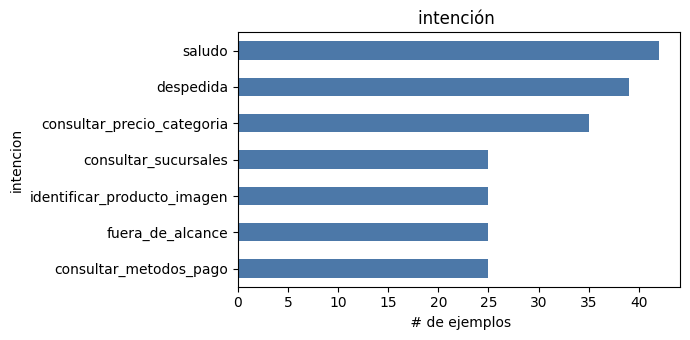

In [ ]:
ax = df_texto["intencion"].value_counts().sort_values().plot.barh(figsize=(7,3.5), color="#4C78A8")
ax.set_title("intención "); ax.set_xlabel(" # de ejemplos")
plt.tight_layout(); plt.savefig("evidencias/dataset_texto_distribucion.png", dpi=150); plt.show()
df_texto.to_csv("evidencias/dataset_texto.csv", index=False)

## 3. Preprocesamiento de texto
Se aplican las 4 técnicas requeridas según el Tema 5:
1. Tokenización RegexpTokenizer.
2. Normalización minúsculas, eliminación de acentos y signos, espacios duplicados.
3. Eliminación de stopwords con lista personalizada
4. Stemming con SnowballStemmer('spanish')

In [ ]:
try:
    from nltk.stem import SnowballStemmer
    _stemmer = SnowballStemmer("spanish")
    def stem(w): return _stemmer.stem(w)
    STEMMER_INFO = "NLTK SnowballStemmer"
except Exception:
    def stem(w):
        for suf in ("aciones","acion","amos","ando","mente","ores","ones","es","s"):
            if w.endswith(suf) and len(w) - len(suf) >= 3: return w[:-len(suf)]
        return w
    STEMMER_INFO = "stemmer respaldo "
print("Stemmer :", STEMMER_INFO)

# Lista de stopwords personalizada (Tema 5.2) se conservan negaciones e interrogativos

STOPWORDS_ES = set("""
a al ante con contra de del desde el la las los lo en entre es esta este esto estos estas ese esa eso
hay para por segun sin sobre tras un una unos unas y o u e ni que se su sus mi mis tu tus me te le les
nos yo usted ustedes ellos ellas muy mas tambien pero porque ya fue son ser soy eres era he ha han
quisiera quiero necesito puedo podria favor""".split())
NEGACIONES = {"no", "nunca", "jamas", "tampoco", "sin"}
STOPWORDS_ES -= NEGACIONES

def normalizar(texto):
    t = str(texto).lower()
    t = unicodedata.normalize("NFD", t)
    t = "".join(c for c in t if unicodedata.category(c) != "Mn")   # quita acentos
    t = re.sub(r"[^a-z0-9\s]", " ", t)                               # quita signos
    return re.sub(r"\s+", " ", t).strip()

def tokenizar(texto):
    return re.findall(r"[a-z0-9]+", texto)

def quitar_stopwords(tokens):
    return [t for t in tokens if t not in STOPWORDS_ES]


# Vocabulario palabras ya normalizadas
VOCABULARIO = sorted({t for x in df_texto["texto"] for t in tokenizar(normalizar(x))})

def corregir_ortografia(tokens, corte=0.8):
    """Reemplaza palabras desconocidas por la más parecida del vocabulario donde similitud >= corte."""
    salida = []
    for t in tokens:
        if t in VOCABULARIO or len(t) < 4 or t.isdigit():
            salida.append(t); continue
        cerca = difflib.get_close_matches(t, VOCABULARIO, n=1, cutoff=corte)
        salida.append(cerca[0] if cerca else t)
    return salida

def preprocesar(texto, usar_stopwords=True, usar_stem=True, devolver_lista=False, corregir=True):
    toks = tokenizar(normalizar(texto))
    if corregir:
        toks = corregir_ortografia(toks)
    if usar_stopwords:
        filtrados = quitar_stopwords(toks)
        toks = filtrados if filtrados else toks
    if usar_stem:
        toks = [stem(t) for t in toks]
    return toks if devolver_lista else " ".join(toks)

# despues de la prueba se agegaron mas palabras
CASOS_DIFICILES += [("garcias", "despedida"), ("grasias por todo", "despedida")]
print(preprocesar("garcias"), "|", preprocesar("kuanto cuesta la ropa"))


Stemmer : NLTK SnowballStemmer
graci | cuant cuest rop


In [ ]:
ejemplos = ["¿Cuánto cuesta la ropa?", "Me puede pasar los precios de los zapatos?", "NO puedo pagar con tarjeta", "kuanto sale un par de sandalias"]
filas = []
for t in ejemplos:
    n = normalizar(t); tk = tokenizar(n); sw = quitar_stopwords(tk)
    filas.append({"original": t, "normalizado": n, "tokens": tk, "sin_stopwords": sw, "stems": [stem(x) for x in sw]})
tabla_prep = pd.DataFrame(filas); display(tabla_prep)
tabla_prep.to_csv("evidencias/ejemplos_preprocesamiento.csv", index=False)

df_texto["texto_proc"] = df_texto["texto"].apply(preprocesar)
print("\nVocabulario SIN preprocesar:", len({w for t in df_texto.texto for w in t.lower().split()}))
print("Vocabulario CON preprocesamiento:", len({w for t in df_texto.texto_proc for w in t.split()}))
df_texto[["texto","texto_proc","intencion"]].head(8)

,original,normalizado,tokens,sin_stopwords,stems
0,¿Cuánto cuesta la ropa?,cuanto cuesta la ropa,"[cuanto, cuesta, la, ropa]","[cuanto, cuesta, ropa]","[cuant, cuest, rop]"
1,Me puede pasar los precios de los zapatos?,me puede pasar los precios de los zapatos,"[me, puede, pasar, los, precios, de, los, zapa...","[puede, pasar, precios, zapatos]","[pued, pas, preci, zapat]"
2,NO puedo pagar con tarjeta,no puedo pagar con tarjeta,"[no, puedo, pagar, con, tarjeta]","[no, pagar, tarjeta]","[no, pag, tarjet]"
3,kuanto sale un par de sandalias,kuanto sale un par de sandalias,"[kuanto, sale, un, par, de, sandalias]","[kuanto, sale, par, sandalias]","[kuant, sal, par, sandali]"



Vocabulario SIN preprocesar: 273
Vocabulario CON preprocesamiento: 201


,texto,texto_proc,intencion
0,hola,hol,saludo
1,hola buenos dias,hol buen dias,saludo
2,buenas tardes,buen tard,saludo
3,buenas noches,buen noch,saludo
4,que tal,tal,saludo
5,buen dia,buen dia,saludo
6,hola necesito ayuda,hol ayud,saludo
7,hey hola,hey hol,saludo


## 4. Representación del texto y clasificación de intenciones
Se comparan Bag of Words vs TF-IDF y Naive Bayes vs SVM lineal (Tema 6).  validación cruzada de 5 pliegues

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

def hacer_pipeline(vec, modelo):
    v = {"bow": CountVectorizer(ngram_range=(1,2)),
         "tfidf": TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True),
         "tfidf_char": TfidfVectorizer(analyzer="char_wb", ngram_range=(2,4), sublinear_tf=True)}[vec]
    m = {"nb": MultinomialNB(alpha=0.5), "svm": CalibratedClassifierCV(LinearSVC(C=1.0, class_weight="balanced"), cv=3)}[modelo]
    return Pipeline([("vec", v), ("clf", m)])

EXPERIMENTOS = {
    "BoW + Naive Bayes":      ("bow","nb"),
    "TF-IDF + Naive Bayes":   ("tfidf","nb"),
    "BoW + SVM":              ("bow","svm"),
    "TF-IDF + SVM":           ("tfidf","svm"),
}

df_dificil = pd.DataFrame(CASOS_DIFICILES, columns=["texto","intencion"])
df_dificil["texto_proc"] = df_dificil["texto"].apply(preprocesar)

X_tr, X_te, y_tr, y_te = train_test_split(df_texto["texto_proc"], df_texto["intencion"],
                                           test_size=0.20, stratify=df_texto["intencion"], random_state=SEED)
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
filas, modelos = [], {}
for nombre, (v, m) in EXPERIMENTOS.items():
    p = hacer_pipeline(v, m)
    cv_pred = cross_val_predict(p, df_texto["texto_proc"], df_texto["intencion"], cv=skf)
    p.fit(X_tr, y_tr); modelos[nombre] = p
    pr = p.predict(X_te)
    P, R, F, _ = precision_recall_fscore_support(y_te, pr, average="macro", zero_division=0)
    _, _, Fcv, _ = precision_recall_fscore_support(df_texto["intencion"], cv_pred, average="macro", zero_division=0)
    filas.append({"modelo": nombre, "accuracy_test": accuracy_score(y_te, pr), "precision_macro": P,
                  "recall_macro": R, "f1_macro": F, "f1_macro_CV5": Fcv,
                  "accuracy_casos_dificiles": accuracy_score(df_dificil["intencion"], p.predict(df_dificil["texto_proc"]))})
tabla_modelos = pd.DataFrame(filas).set_index("modelo").round(3)
display(tabla_modelos)
tabla_modelos.to_csv("evidencias/comparacion_modelos_texto.csv")

,accuracy_test,precision_macro,recall_macro,f1_macro,f1_macro_CV5,accuracy_casos_dificiles
modelo,,,,,,
BoW + Naive Bayes,0.864,0.782,0.839,0.804,0.777,0.727
TF-IDF + Naive Bayes,0.864,0.782,0.839,0.804,0.783,0.727
BoW + SVM,0.909,0.910,0.896,0.898,0.883,0.727
TF-IDF + SVM,0.932,0.924,0.925,0.923,0.890,0.727


Modelo seleccionado : TF-IDF + SVM
                             precision    recall  f1-score   support

     consultar_metodos_pago       0.80      0.80      0.80         5
 consultar_precio_categoria       1.00      1.00      1.00         7
       consultar_sucursales       1.00      1.00      1.00         5
                  despedida       1.00      0.88      0.93         8
           fuera_de_alcance       0.67      0.80      0.73         5
identificar_producto_imagen       1.00      1.00      1.00         5
                     saludo       1.00      1.00      1.00         9

                   accuracy                           0.93        44
                  macro avg       0.92      0.92      0.92        44
               weighted avg       0.94      0.93      0.93        44



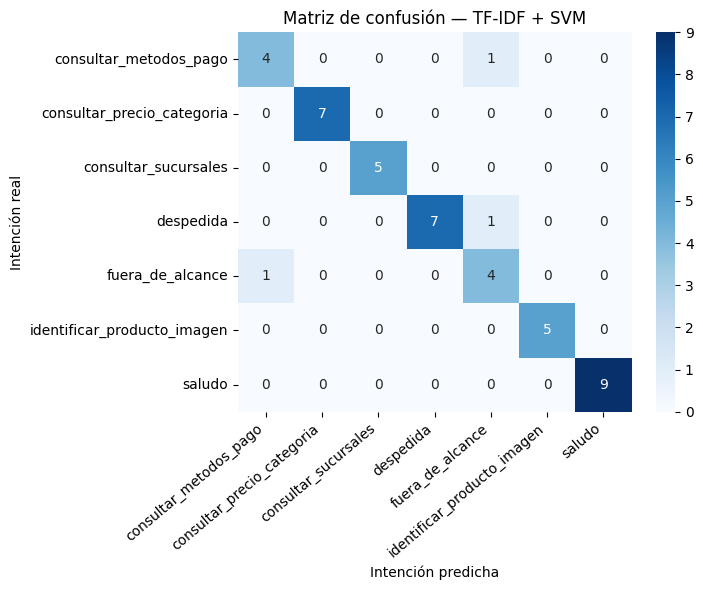

Errores en test: 3 de 44


,texto,real,predicha
25,como tramito mi tarjeta de la tienda,fuera_de_alcance,consultar_metodos_pago
28,grax,despedida,fuera_de_alcance
41,en efectivo se puede,consultar_metodos_pago,fuera_de_alcance


In [ ]:
MEJOR = tabla_modelos["f1_macro_CV5"].idxmax()
print("Modelo seleccionado :", MEJOR)
mejor = modelos[MEJOR]
pred_te = mejor.predict(X_te)
reporte = classification_report(y_te, pred_te, zero_division=0, output_dict=True)
print(classification_report(y_te, pred_te, zero_division=0))
pd.DataFrame(reporte).T.round(3).to_csv("evidencias/reporte_clasificacion_texto.csv")

clases_txt = sorted(df_texto["intencion"].unique())
cm = confusion_matrix(y_te, pred_te, labels=clases_txt)
plt.figure(figsize=(7.5,6)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=clases_txt, yticklabels=clases_txt)
plt.xlabel("Intención predicha"); plt.ylabel("Intención real"); plt.title(f"Matriz de confusión — {MEJOR}")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.savefig("evidencias/matriz_confusion_texto.png", dpi=150); plt.show()

err = pd.DataFrame({"texto": X_te.index.map(lambda i: df_texto.loc[i,"texto"]), "real": y_te.values, "predicha": pred_te})
err = err[err.real != err.predicha]; print(f"Errores en test: {len(err)} de {len(y_te)}"); display(err)
err.to_csv("evidencias/errores_texto.csv", index=False)

In [ ]:
# Casos difíciles, análisis de umbral de confianza fallback
proba = mejor.predict_proba(df_dificil["texto_proc"]); clases_m = mejor.classes_
df_dificil["predicha"] = clases_m[proba.argmax(1)]; df_dificil["confianza"] = proba.max(1).round(2)
df_dificil["correcto"] = df_dificil["predicha"] == df_dificil["intencion"]
display(df_dificil[["texto","intencion","predicha","confianza","correcto"]])
df_dificil.to_csv("evidencias/casos_dificiles.csv", index=False)

res_umbral = []
for th in [0.0, 0.3, 0.4, 0.5, 0.6, 0.7]:
    m = df_dificil["confianza"] >= th
    res_umbral.append({"umbral": th, "cobertura": m.mean().round(2),
                       "accuracy_en_aceptadas": df_dificil.loc[m,"correcto"].mean().round(2) if m.any() else np.nan})
tabla_umbral = pd.DataFrame(res_umbral); display(tabla_umbral)
tabla_umbral.to_csv("evidencias/analisis_umbral.csv", index=False)

,texto,intencion,predicha,confianza,correcto
0,cuanto cuesta enviar un paquete,fuera_de_alcance,consultar_precio_categoria,0.63,False
1,kuanto cuesta la ropa,consultar_precio_categoria,consultar_precio_categoria,0.91,True
2,presio de zapatos,consultar_precio_categoria,consultar_precio_categoria,0.89,True
3,aceptan bitcoin,fuera_de_alcance,consultar_metodos_pago,0.77,False
4,cuanto vale una laptop,consultar_precio_categoria,consultar_precio_categoria,0.87,True
5,donde pago mi recibo de luz,fuera_de_alcance,consultar_precio_categoria,0.45,False
6,en que lugares venden,consultar_sucursales,fuera_de_alcance,0.46,False
7,gracias por la informacion,despedida,despedida,0.92,True
8,buenas tardes quiero saber precios,saludo,saludo,0.57,True
9,pago con tarjeta,consultar_metodos_pago,consultar_metodos_pago,0.90,True


,umbral,cobertura,accuracy_en_aceptadas
0,0.0,1.00,0.73
1,0.3,1.00,0.73
2,0.4,1.00,0.73
3,0.5,0.91,0.80
4,0.6,0.77,0.88
5,0.7,0.68,0.93


In [ ]:
UMBRAL_TEXTO = 0.60      # cobertura vs accuracy
# Modelo de producción: se reentrena con TODOS los datos tras haber evaluado
clf_texto = hacer_pipeline(*EXPERIMENTOS[MEJOR]).fit(df_texto["texto_proc"], df_texto["intencion"])
def predecir_intencion(mensaje):
    p = clf_texto.predict_proba([preprocesar(mensaje)])[0]
    i = int(p.argmax()); return clf_texto.classes_[i], float(p[i])
print(predecir_intencion("cuanto cuestan los tenis"), predecir_intencion("quiero cancelar mi pedido"))

('consultar_precio_categoria', 0.9333153268860164) ('fuera_de_alcance', 0.7708414878893192)


### 4.1 Extracción de entidades
Resuelve sinónimos tenis → Zapatos y valida contra las categorías reales del CSV; si no encuentra categoría devuelve None (el bot pedirá aclaración, y no precios en cero).

In [ ]:
SINONIMOS = {
 "ropa": ["ropa","camisa","pantalon","vestido","falda","blusa","short","playera","chamarra","sudadera","abrigo"],
 "zapatos": ["zapato","zapatos","tenis","bota","botas","sandalia","sandalias","calzado","tacones"],
 "tecnologia": ["tecnologia","celular","laptop","computadora","tablet","televisor","audifonos","smartphone","telefono"],
 "cosmeticos": ["cosmetico","cosmeticos","maquillaje","perfume","labial","crema","shampoo"],
 "libros": ["libro","libros","novela","revista"],
 "juguetes": ["juguete","juguetes","muneca","peluche","lego","videojuego"],
 "comida": ["comida","alimento","alimentos","bebida","snack"],
 "souvenir": ["souvenir","souvenirs","recuerdo","recuerdos","regalo"],
}
_norm = lambda s: normalizar(s)
CATS_NORM = {_norm(c): c for c in CATEGORIAS_REALES}
IDX_SIN = {stem(_norm(s)): concepto for concepto, lst in SINONIMOS.items() for s in lst}

def concepto_a_categoria_csv(concepto):
    # Resuelve 'juguetes' -> 'Jueguetes'
    m = difflib.get_close_matches(_norm(concepto), list(CATS_NORM), n=1, cutoff=0.6)
    return CATS_NORM[m[0]] if m else None

def detectar_categoria(mensaje):
    for tk in tokenizar(normalizar(mensaje)):
        s = stem(tk); concepto = IDX_SIN.get(s)
        if concepto is None:
            # tolerancia a faltas de ortografía
            cerca = difflib.get_close_matches(s, list(IDX_SIN), n=1, cutoff=0.85)
            concepto = IDX_SIN[cerca[0]] if cerca else None
        if concepto: return concepto_a_categoria_csv(concepto)
    return None

def stats_precio(cat_real):
    s = df_tiendas.loc[df_tiendas["categoria"] == cat_real, "precio"]
    return {"n": int(s.size), "promedio": float(s.mean()), "mediana": float(s.median()),
            "min": float(s.min()), "max": float(s.max())}

for t in ["cuanto cuesta la ropa","precio de unos tenis","cuanto cuestan los juguetes","precio de un perfume","cuanto sale un coche"]:
    print(f"{t!r:45} -> {detectar_categoria(t)}")

'cuanto cuesta la ropa'                       -> Ropa
'precio de unos tenis'                        -> Zapatos
'cuanto cuestan los juguetes'                 -> Juguete
'precio de un perfume'                        -> Cosmeticos
'cuanto sale un coche'                        -> None


### 4.2 Chatbot  texto
Avance 1, ahora con clasificador supervisado, umbral de confianza y manejo de categoría no encontrada.

In [ ]:
MONEDA = "unidades monetarias del dataset"

def responder_texto(mensaje):
    intent, conf = predecir_intencion(mensaje)
    if conf < UMBRAL_TEXTO: intent_ef = "desconocida"
    else: intent_ef = intent
    if intent_ef == "saludo":
        r = "¡Hola! Puedo ayudarte con precios por categoría, métodos de pago, sucursales o identificar un producto a partir de una foto."
    elif intent_ef == "consultar_precio_categoria":
        cat = detectar_categoria(mensaje)
        if cat is None:
            r = "No identifiqué la categoría. Las que manejo son: " + ", ".join(CATEGORIAS_REALES) + ". ¿Cuál te interesa?"
        else:
            s = stats_precio(cat)
            r = (f"Para '{cat}' el precio promedio registrado es {s['promedio']:.2f} ; "
                 f"rango {s['min']:.2f} a {s['max']:.2f}; {s['n']:,} ventas.")
            #, en {MONEDA}(mediana {s['mediana']:.2f}
    elif intent_ef == "consultar_metodos_pago":
        r = "Métodos de pago registrados: " + ", ".join(METODOS_PAGO) + "."
    elif intent_ef == "consultar_sucursales":
        r = "Sucursales registradas: " + ", ".join(SUCURSALES) + "."
    elif intent_ef == "identificar_producto_imagen":
        r = "Claro, envíame la foto del producto y te digo a qué categoría corresponde."
    elif intent_ef == "despedida":
        r = "¡Gracias por escribir! Quedo a tu disposición."
    elif intent_ef == "fuera_de_alcance":
        r = "Eso está fuera de lo que puedo resolver por ahora. Puedo ayudarte con precios de categorias, métodos de pago, sucursales o identificar productos por foto."
    else:
        r = "No estoy seguro de haber entendido. Prueba con: 'precio de ropa', 'formas de pago', 'sucursales' o 'te mando una foto'."
    return {"intencion": intent, "confianza": round(conf,2), "intencion_efectiva": intent_ef, "respuesta": r}

for t in ["hola","cuanto cuesta la ropa","precio de algo","aceptan tarjeta","en que plazas estan","quiero cancelar mi pedido","gracias"]:
    o = responder_texto(t); print(f"U: {t}\n   [{o['intencion_efectiva']} | {o['confianza']}] {o['respuesta']}\n")

U: hola
   [saludo | 0.95] ¡Hola! Puedo ayudarte con precios por categoría, métodos de pago, sucursales o identificar un producto a partir de una foto.

U: cuanto cuesta la ropa
   [consultar_precio_categoria | 0.94] Para 'Ropa' el precio promedio registrado es 901.08 ; rango 300.08 a 1500.40; 34,487 ventas).

U: precio de algo
   [consultar_precio_categoria | 0.96] No identifiqué la categoría. Las que manejo son: Comida, Cosmeticos, Juguete, Libros, Ropa, Souvenir, Tecnologia, Zapatos. ¿Cuál te interesa?

U: aceptan tarjeta
   [consultar_metodos_pago | 0.91] Métodos de pago registrados: Efectivo, TarjetaCredito, TarjetaDebito.

U: en que plazas estan
   [consultar_sucursales | 0.82] Sucursales registradas: Istinye Park, Kanyon, Mall of Istanbul, Metrocity, Metropol AVM, Viaport Outlet, Zorlu Center.

U: quiero cancelar mi pedido
   [fuera_de_alcance | 0.77] Eso está fuera de lo que puedo resolver por ahora. Puedo ayudarte con precios de categorias, métodos de pago, sucursales o identi

## 5. Conjunto de imágenes y preparación de datos
Estructura requerida con las categorías del CSV
```
imagenes/
  ropa/  zapatos/  cosmeticos/  libros/  juguetes/   (mínimo 3–5 clases, ≥ 100 imágenes por clase recomendado)
```
Sube un `.zip` con esa estructura o monta Google Drive y cambia `RUTA_IMG` (Tema 8): redimensionamiento a 224×224, división estratificada 70/15/15, aumento de datos solo en entrenamiento, y `preprocess_input` propio de ResNet50

In [ ]:
import zipfile, glob
RUTA_IMG = "imagenes"
if not os.path.isdir(RUTA_IMG):
    try:
        from google.colab import files
        print("Sube el .zip con la carpeta imagenes/")
        z = list(files.upload().keys())[0]
        with zipfile.ZipFile(z) as f: f.extractall(".")
    except Exception as e:
        print("No se pudo cargar el archivo imagenes.zip:", e)
assert os.path.isdir(RUTA_IMG), "Falta la carpeta 'imagenes/'. verificar la estructura "

Sube el .zip con la carpeta imagenes/


Saving imagenes.zip to imagenes.zip


,imagenes
cosmeticos,150
ropa,150
zapatos,150


Train 315 | Val 67 | Test 68


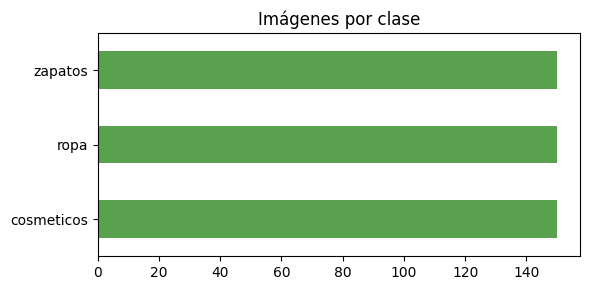

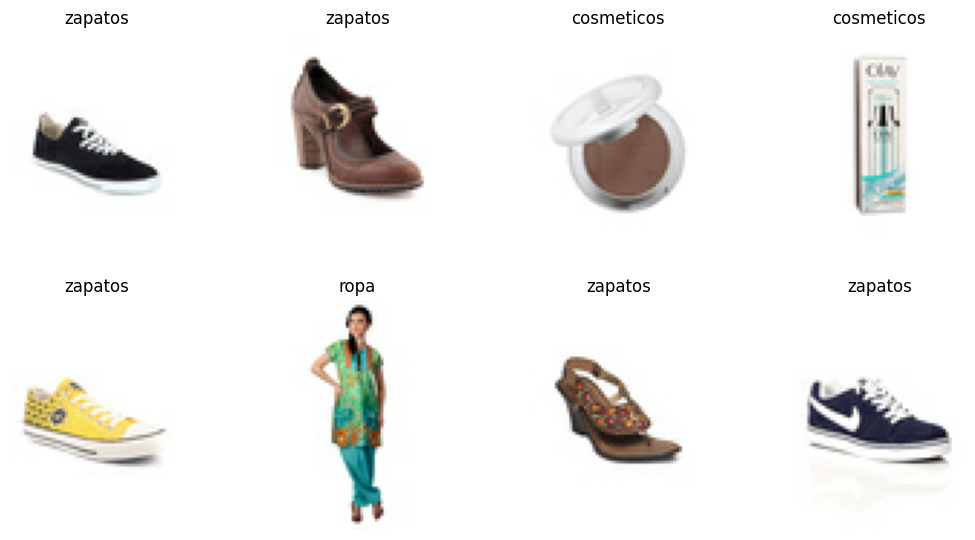

In [ ]:
import tensorflow as tf
tf.keras.utils.set_random_seed(SEED) # reduce variacion

from sklearn.utils.class_weight import compute_class_weight
IMG, BATCH, EPOCHS_1, EPOCHS_FT = 224, 32, 12, 8
EXT = (".jpg", ".jpeg", ".png", ".bmp")
CLASES_IMG = sorted(d for d in os.listdir(RUTA_IMG) if os.path.isdir(os.path.join(RUTA_IMG, d)))
rutas, etiquetas = [], []
for i, c in enumerate(CLASES_IMG):
    for f in os.listdir(os.path.join(RUTA_IMG, c)):
        if f.lower().endswith(EXT): rutas.append(os.path.join(RUTA_IMG, c, f)); etiquetas.append(i)
rutas, etiquetas = np.array(rutas), np.array(etiquetas)
conteo = pd.Series([CLASES_IMG[i] for i in etiquetas]).value_counts().rename("imagenes"); display(conteo.to_frame())
assert len(CLASES_IMG) >= 3 and conteo.min() >= 20, "Se requieren ≥3 clases y ≥20 imágenes por clase ."

r_tr, r_tmp, y_tr_i, y_tmp = train_test_split(rutas, etiquetas, test_size=0.30, stratify=etiquetas, random_state=SEED)
r_va, r_te, y_va_i, y_te_i = train_test_split(r_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(f"Train {len(r_tr)} | Val {len(r_va)} | Test {len(r_te)}")
pd.DataFrame({"clase": CLASES_IMG, "train": np.bincount(y_tr_i), "val": np.bincount(y_va_i), "test": np.bincount(y_te_i)}).to_csv("evidencias/dataset_imagenes_particion.csv", index=False)
json.dump(CLASES_IMG, open("evidencias/clases_imagenes.json", "w"))

conteo.sort_values().plot.barh(figsize=(6,3), color="#59A14F"); plt.title("Imágenes por clase"); plt.tight_layout()
plt.savefig("evidencias/dataset_imagenes_distribucion.png", dpi=150); plt.show()

def cargar(ruta, y):
    img = tf.io.decode_image(tf.io.read_file(ruta), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG, IMG)); img.set_shape((IMG, IMG, 3)); return img, y
def hacer_ds(r, y, train=False):
    ds = tf.data.Dataset.from_tensor_slices((r, y))
    if train: ds = ds.shuffle(len(r), seed=SEED)
    return ds.map(cargar, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)
ds_tr, ds_va, ds_te = hacer_ds(r_tr, y_tr_i, True), hacer_ds(r_va, y_va_i), hacer_ds(r_te, y_te_i)

# Muestra de imágenes
fig, axs = plt.subplots(2, 4, figsize=(11, 5.5))
for ax, i in zip(axs.ravel(), np.random.choice(len(rutas), 8, replace=False)):
    ax.imshow(plt.imread(rutas[i]) if rutas[i].lower().endswith(".png") else tf.io.decode_image(tf.io.read_file(rutas[i]), channels=3).numpy())
    ax.set_title(CLASES_IMG[etiquetas[i]]); ax.axis("off")
plt.tight_layout(); plt.savefig("evidencias/muestra_imagenes.png", dpi=150); plt.show()

## 6. Clasificador visual CNN con transferencia de aprendizaje
- Fase 1: Utilizando una ResNet50 preentrenada en ImageNet con el backbone congelado, procediendo a entrenar exclusivamente el nuevo clasificador (GlobalAveragePooling seguido de Dropout y una capa densa con activación softmax)
- Fase 2 (fine-tuning): se descongelan las últimas capas con learning rate bajo (BatchNorm permanece congelada).
- Desbalance: class_weight (Tema 10). Aumento de datos: flip horizontal, rotación, zoom y contraste.

In [ ]:
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
N_CLASES = len(CLASES_IMG)

def construir_modelo():
    aug = tf.keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.08),
                               layers.RandomZoom(0.10), layers.RandomContrast(0.10)], name="aumento_datos")
    base = ResNet50(include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3)); base.trainable = False
    inp = layers.Input((IMG, IMG, 3))
    x = aug(inp)
    x = layers.Lambda(preprocess_input, name="preprocess_resnet50")(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x); x = layers.Dropout(0.3)(x)
    out = layers.Dense(N_CLASES, activation="softmax")(x)
    return tf.keras.Model(inp, out), base

modelo, base = construir_modelo()
cw = compute_class_weight("balanced", classes=np.arange(N_CLASES), y=y_tr_i); cw = {i: w for i, w in enumerate(cw)}
cb = [tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
      tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2)]
modelo.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h1 = modelo.fit(ds_tr, validation_data=ds_va, epochs=EPOCHS_1, class_weight=cw, callbacks=cb)
modelo.save_weights("evidencias/resnet50_fase1.weights.h5")
val1 = max(h1.history["val_accuracy"]); print("Mejor val_accuracy fase 1:", round(val1, 3))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/12
10/10 ━━━━━━━━━━━━━━━━━━━━ 90s 9s/step - accuracy: 0.7302 - loss: 0.6334 - val_accuracy: 0.9851 - val_loss: 0.1739 - learning_rate: 0.0010
Epoch 2/12
10/10 ━━━━━━━━━━━━━━━━━━━━ 80s 8s/step - accuracy: 0.9524 - loss: 0.1754 - val_accuracy: 1.0000 - val_loss: 0.0792 - learning_rate: 0.0010
Epoch 3/12
10/10 ━━━━━━━━━━━━━━━━━━━━ 86s 8s/step - accuracy: 0.9619 - loss: 0.0955 - val_accuracy: 1.0000 - val_loss: 0.0700 - learning_rate: 0.0010
Epoch 4/12
10/10 ━━━━━━━━━━━━━━━━━━━━ 80s 8s/step - accuracy: 0.9778 - loss: 0.0735 - val_accuracy: 1.0000 - val_loss: 0.0439 - learning_rate: 0.0010
Epoch 5/12
10/10 ━━━━━━━━━━━━━━━━━━━━ 74s 7s/step - accuracy: 0.9905 - loss: 0.0415 - val_accuracy: 1.0000 - val_loss: 0.0308 - learning_rate: 0.0010
Epoch 6/12
10/10 ━━━━━━━━━━━━━━━━━━━━ 80s 8s/step - accuracy: 0.9968 - loss: 0.0334 - val_accuracy: 1.0000 - val_loss: 0.0304 - learning_rate: 0.0010
Mejor val_accuracy fase 1: 1.0


Epoch 1/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 116s 11s/step - accuracy: 0.9746 - loss: 0.0857 - val_accuracy: 1.0000 - val_loss: 0.0441 - learning_rate: 1.0000e-05
Epoch 2/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 95s 10s/step - accuracy: 1.0000 - loss: 0.0245 - val_accuracy: 1.0000 - val_loss: 0.0173 - learning_rate: 1.0000e-05
Epoch 3/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 96s 10s/step - accuracy: 0.9968 - loss: 0.0160 - val_accuracy: 1.0000 - val_loss: 0.0086 - learning_rate: 1.0000e-05
Epoch 4/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 150s 11s/step - accuracy: 0.9968 - loss: 0.0086 - val_accuracy: 1.0000 - val_loss: 0.0141 - learning_rate: 1.0000e-05
Mejor val_accuracy fine-tuning: 1.0


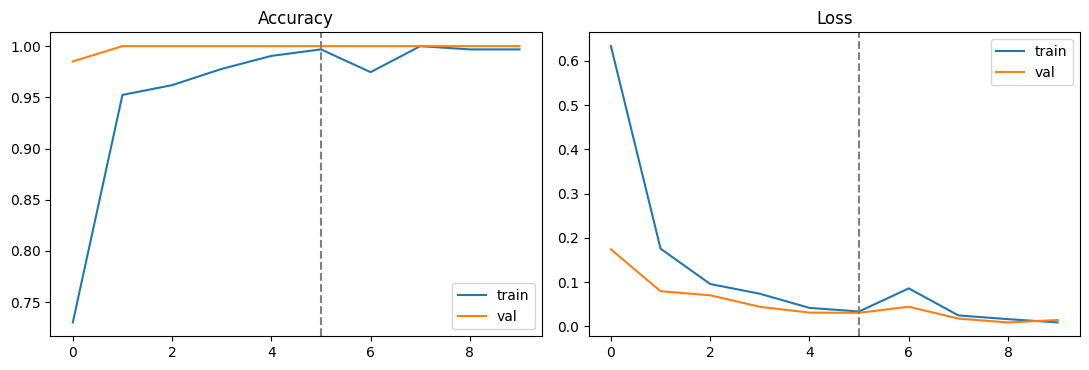

In [ ]:
# Fine-tuning controlado
base.trainable = True
for capa in base.layers[:-30]: capa.trainable = False
for capa in base.layers:
    if isinstance(capa, layers.BatchNormalization): capa.trainable = False
modelo.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = modelo.fit(ds_tr, validation_data=ds_va, epochs=EPOCHS_FT, class_weight=cw, callbacks=cb)
val2 = max(h2.history["val_accuracy"]); print("Mejor val_accuracy fine-tuning:", round(val2, 3))
if val2 < val1:
    print("El fine-tuning no mejoró en validación: se restaura la fase 1.")
    modelo.load_weights("evidencias/resnet50_fase1.weights.h5"); MODELO_FINAL = "ResNet50 (transfer learning, base congelada)"
else:
    MODELO_FINAL = "ResNet50 (transfer learning + fine-tuning)"
modelo.save_weights("evidencias/resnet50_final.weights.h5")

hist = {k: h1.history[k] + h2.history[k] for k in ["accuracy","val_accuracy","loss","val_loss"]}
fig, ax = plt.subplots(1, 2, figsize=(11,3.8))
ax[0].plot(hist["accuracy"], label="train"); ax[0].plot(hist["val_accuracy"], label="val"); ax[0].axvline(len(h1.history["loss"])-1, ls="--", c="gray"); ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(hist["loss"], label="train"); ax[1].plot(hist["val_loss"], label="val"); ax[1].axvline(len(h1.history["loss"])-1, ls="--", c="gray"); ax[1].set_title("Loss"); ax[1].legend()
plt.tight_layout(); plt.savefig("evidencias/curvas_entrenamiento.png", dpi=150); plt.show()

### 6.1 Evaluación en el conjunto de prueba

3/3 ━━━━━━━━━━━━━━━━━━━━ 18s 4s/step
Accuracy 1.000 | Precision(macro) 1.000 | Recall(macro) 1.000 | F1(macro) 1.000
              precision    recall  f1-score   support

  cosmeticos       1.00      1.00      1.00        22
        ropa       1.00      1.00      1.00        23
     zapatos       1.00      1.00      1.00        23

    accuracy                           1.00        68
   macro avg       1.00      1.00      1.00        68
weighted avg       1.00      1.00      1.00        68



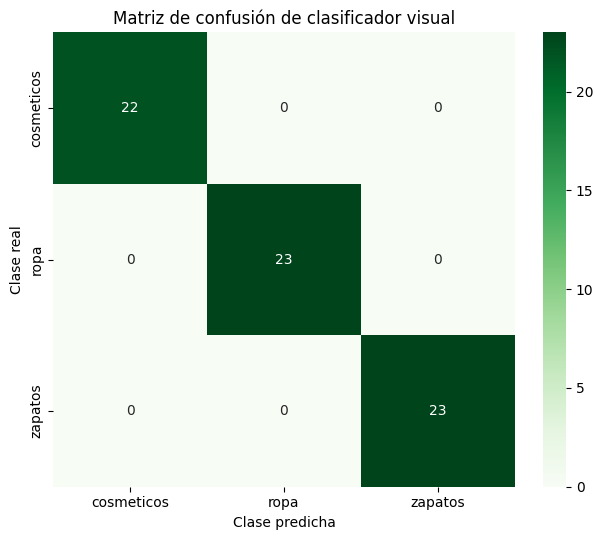

Imágenes mal clasificadas: 0 de 68


In [ ]:
y_true = np.concatenate([y.numpy() for _, y in ds_te]); probs_te = modelo.predict(ds_te); y_pred = probs_te.argmax(1)
acc = accuracy_score(y_true, y_pred)
P, R, F, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
Pw, Rw, Fw, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
metricas_img = {"modelo": MODELO_FINAL, "accuracy": acc, "precision_macro": P, "recall_macro": R, "f1_macro": F,
                "precision_weighted": Pw, "recall_weighted": Rw, "f1_weighted": Fw, "n_test": int(len(y_true)), "clases": CLASES_IMG}
json.dump(metricas_img, open("evidencias/metricas_imagen.json", "w"), indent=2, ensure_ascii=False)
print(f"Accuracy {acc:.3f} | Precision(macro) {P:.3f} | Recall(macro) {R:.3f} | F1(macro) {F:.3f}")
print(classification_report(y_true, y_pred, target_names=CLASES_IMG, zero_division=0))
pd.DataFrame(classification_report(y_true, y_pred, target_names=CLASES_IMG, zero_division=0, output_dict=True)).T.round(3).to_csv("evidencias/reporte_clasificacion_imagen.csv")

cm_i = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6.5,5.5)); sns.heatmap(cm_i, annot=True, fmt="d", cmap="Greens", xticklabels=CLASES_IMG, yticklabels=CLASES_IMG)
plt.xlabel("Clase predicha"); plt.ylabel("Clase real"); plt.title("Matriz de confusión de clasificador visual")
plt.tight_layout(); plt.savefig("evidencias/matriz_confusion_imagen.png", dpi=150); plt.show()

# analizando los errores
mal = np.where(y_pred != y_true)[0]; print("Imágenes mal clasificadas:", len(mal), "de", len(y_true))
if len(mal):
    fig, axs = plt.subplots(1, min(5, len(mal)), figsize=(3*min(5, len(mal)), 3.4)); axs = np.atleast_1d(axs)
    for ax, i in zip(axs, mal[:5]):
        ax.imshow(tf.io.decode_image(tf.io.read_file(r_te[i]), channels=3).numpy()); ax.axis("off")
        ax.set_title(f"real: {CLASES_IMG[y_true[i]]}\npred: {CLASES_IMG[y_pred[i]]} ({probs_te[i].max():.0%})", fontsize=9)
    plt.tight_layout(); plt.savefig("evidencias/errores_imagen.png", dpi=150); plt.show()

## 7. Integración multimodal texto-imagen(visual)
El asistente ejecuta las 3 operaciones requeridas:
1. Procesamiento de texto(preprocesamiento + clasificación de intención + extracción de entidad).
2. Clasificación de imagen con la CNN (con top 3 con probabilidades).
3. Comunicación/interpretación del resultado (categoría detectada + confianza + estadísticas de precio del CSV, o petición de otra foto si la confianza es baja).

In [ ]:
UMBRAL_IMG = 0.60
def predecir_imagen(ruta):
    img = tf.io.decode_image(tf.io.read_file(ruta), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG, IMG))[None, ...]
    p = modelo.predict(img, verbose=0)[0]; orden = p.argsort()[::-1][:3]
    return [(CLASES_IMG[i], float(p[i])) for i in orden]

def responder_multimodal(mensaje, ruta_imagen=None):
    ops = {"1_texto_procesado": False, "2_imagen_clasificada": False, "3_resultado_comunicado": False}
    intent, conf = predecir_intencion(mensaje); ops["1_texto_procesado"] = True
    intent_ef = intent if conf >= UMBRAL_TEXTO else "desconocida"
    top3 = None
    usa_imagen = ruta_imagen is not None and intent_ef in ("identificar_producto_imagen", "consultar_precio_categoria")
    if usa_imagen:
        top3 = predecir_imagen(ruta_imagen); ops["2_imagen_clasificada"] = True
        cat_img, p_img = top3[0]
        if p_img >= UMBRAL_IMG:
            cat_csv = concepto_a_categoria_csv(cat_img)
            texto = f"La imagen identifico un producto de la categoría '{cat_img}' (%confianza {p_img:.0%})."
            if cat_csv:
                s = stats_precio(cat_csv)
                texto += f" En el catálogo, '{cat_csv}' tiene un precio promedio de {s['promedio']:.2f} (rango {s['min']:.2f}–{s['max']:.2f})."
            respuesta = texto
        else:
            alt = ", ".join(f"{c} ({p:.0%})" for c, p in top3[:2])
            respuesta = f"No estoy seguro de qué producto es ( mejores opciones: {alt}). ¿Puedes enviar otra foto con mejor luz o encuadre?"
        ops["3_resultado_comunicado"] = True
    elif intent_ef == "identificar_producto_imagen":
        respuesta = "Con gusto, envíame la imagen del producto para clasificarla."; ops["3_resultado_comunicado"] = True
    else:
        respuesta = responder_texto(mensaje)["respuesta"]; ops["3_resultado_comunicado"] = True
    return {"mensaje": mensaje, "imagen": os.path.basename(ruta_imagen) if ruta_imagen else None, "intencion": intent_ef,
            "conf_texto": round(conf, 2), "top3_imagen": top3, "respuesta": respuesta, **ops}

# demostración con imágenes del conjunto de prueba que no fueron usadas en el entrenamiento
escenarios = [("hola", None), ("quiero identificar un producto con una foto", None)]
vistas = set()
for r, y in zip(r_te, y_te_i):
    if y not in vistas and len(vistas) < 3:
        vistas.add(y); escenarios.append(("te mando una foto, que categoria es", r)); escenarios.append(("cuanto cuesta esto", r))
escenarios += [("aceptan tarjeta de credito", None), ("quiero cancelar mi pedido", None), ("gracias", None)]
demo = pd.DataFrame([responder_multimodal(m, r) for m, r in escenarios])
pd.set_option("display.max_colwidth", 140); display(demo[["mensaje","imagen","intencion","conf_texto","respuesta","1_texto_procesado","2_imagen_clasificada","3_resultado_comunicado"]])
demo.to_csv("evidencias/demo_integracion.csv", index=False)

,mensaje,imagen,intencion,conf_texto,respuesta,1_texto_procesado,2_imagen_clasificada,3_resultado_comunicado
0,hola,None,saludo,0.95,"¡Hola! Puedo ayudarte con precios por categoría, métodos de pago, sucursales o identificar un producto a partir de una foto.",True,False,True
1,quiero identificar un producto con una foto,None,identificar_producto_imagen,0.92,"Con gusto, envíame la imagen del producto para clasificarla.",True,False,True
2,"te mando una foto, que categoria es",24403.jpg,identificar_producto_imagen,0.92,"La imagen identifico un producto de la categoría 'ropa' (%confianza 100%). En el catálogo, 'Ropa' tiene un precio promedio de 901.08 (ra...",True,True,True
3,cuanto cuesta esto,24403.jpg,consultar_precio_categoria,0.95,"La imagen identifico un producto de la categoría 'ropa' (%confianza 100%). En el catálogo, 'Ropa' tiene un precio promedio de 901.08 (ra...",True,True,True
4,"te mando una foto, que categoria es",27077.jpg,identificar_producto_imagen,0.92,"La imagen identifico un producto de la categoría 'zapatos' (%confianza 99%). En el catálogo, 'Zapatos' tiene un precio promedio de 1807....",True,True,True
5,cuanto cuesta esto,27077.jpg,consultar_precio_categoria,0.95,"La imagen identifico un producto de la categoría 'zapatos' (%confianza 99%). En el catálogo, 'Zapatos' tiene un precio promedio de 1807....",True,True,True
6,"te mando una foto, que categoria es",44183.jpg,identificar_producto_imagen,0.92,"La imagen identifico un producto de la categoría 'cosmeticos' (%confianza 99%). En el catálogo, 'Cosmeticos' tiene un precio promedio de...",True,True,True
7,cuanto cuesta esto,44183.jpg,consultar_precio_categoria,0.95,"La imagen identifico un producto de la categoría 'cosmeticos' (%confianza 99%). En el catálogo, 'Cosmeticos' tiene un precio promedio de...",True,True,True
8,aceptan tarjeta de credito,None,consultar_metodos_pago,0.92,"Métodos de pago registrados: Efectivo, TarjetaCredito, TarjetaDebito.",True,False,True
9,quiero cancelar mi pedido,None,fuera_de_alcance,0.77,"Eso está fuera de lo que puedo resolver por ahora. Puedo ayudarte con precios de categorias, métodos de pago, sucursales o identificar p...",True,False,True


In [ ]:
# CHAT INTERACTIVO MULTIMODAL TEXTO E IMAGEN(VISUAL)
from google.colab import files

INTENTS_CON_IMAGEN = ("identificar_producto_imagen", "consultar_precio_categoria")
historial = []

def pedir_imagen():
    print("AsistenteVirtual: Busca y selecciona la fotografía del producto en la ventana que aparecerá...")
    subida = files.upload()
    return list(subida.keys())[0] if subida else None

print("AsistenteVirtual: ¡Hola! Puedo ayudarte con precios de categorias, métodos de pago, sucursales o identificar un producto por foto.")
print("           (Escribe 'salir' para terminar)\n")

while True:
    msg = input("Tú: ").strip()
    if not msg:
        continue
    if msg.lower() in ("salir", "exit", "quit"):
        print("AsistenteVirtual: ¡Hasta luego!"); break

    # primer pase solo con texto para conocer la intención
    r0 = responder_multimodal(msg)
    ruta = None

    if r0["intencion"] == "identificar_producto_imagen":
        print("AsistenteVirtual: Claro que sí, mándame la foto del artículo.")
        ruta = pedir_imagen()

    elif r0["intencion"] == "consultar_precio_categoria" and detectar_categoria(msg) is None:
        # pregunta de precio sin categoría en el texto: la imagen puede resolverla
        resp = input("AsistenteVirtual: No identifiqué la categoría. ¿Quieres adjuntar una foto del producto? (s/n): ").strip().lower()
        if resp in ("s", "si", "sí"):
            ruta = pedir_imagen()

    r = responder_multimodal(msg, ruta)
    print("\nAsistenteVirtual:", r["respuesta"])
    if r["top3_imagen"]:
        print("   Top 3 imagen:", [(c, f"{p:.0%}") for c, p in r["top3_imagen"]])
    print()
    historial.append(r)
    if r["intencion"] == "despedida":
        break

pd.DataFrame(historial).to_csv("evidencias/conversacion_interactiva.csv", index=False)


AsistenteVirtual: ¡Hola! Puedo ayudarte con precios de categorias, métodos de pago, sucursales o identificar un producto por foto.
           (Escribe 'salir' para terminar)

Tú: Hola

AsistenteVirtual: ¡Hola! Puedo ayudarte con precios por categoría, métodos de pago, sucursales o identificar un producto a partir de una foto.

Tú: cuanto cuesta un pantalon de mexclilla

AsistenteVirtual: Para 'Ropa' el precio promedio registrado es 901.08 ; rango 300.08 a 1500.40; 34,487 ventas).

Tú: quiero saber un precio
AsistenteVirtual: No identifiqué la categoría. ¿Quieres adjuntar una foto del producto? (s/n): s
AsistenteVirtual: Busca y selecciona la fotografía del producto en la ventana que aparecerá...


Saving foto.png to foto (1).png

AsistenteVirtual: La imagen identifico un producto de la categoría 'ropa' (%confianza 100%). En el catálogo, 'Ropa' tiene un precio promedio de 901.08 (rango 300.08–1500.40).
   Top 3 imagen: [('ropa', '100%'), ('zapatos', '0%'), ('cosmeticos', '0%')]

Tú: garcias

AsistenteVirtual: ¡Gracias por escribir! Quedo a tu disposición.

